# Notebook 2 — Keyword Search, Hybrid Search, and Reranking

Notebook 1 changed what goes into the search and what comes out. This notebook changes the
search itself. Vector search finds meaning, but it can blur exact words such as numbers and
names. **Keyword search** catches those, **hybrid search** combines both, and a **reranker**
takes a second, more careful look at the short list. We build everything with LlamaIndex,
the framework of the profile chat in Stage 2.

**What you will learn**

1. How **BM25** ranks chunks by exact words, and where it beats vector search.
2. How **hybrid search** merges vector and BM25 results with reciprocal rank fusion.
3. How **auto-merging** swaps small matching pieces for their larger parent.
4. How a **cross-encoder** and an **LLM reranker** reorder a candidate list, and what each
   one costs.
5. Which method to reach for, and when.

**Before you start**

```bash
ollama pull nomic-embed-text
ollama pull gpt-oss:20b
uv sync
```

The cross-encoder (about 90 MB) downloads once from Hugging Face; no account is needed.
Then choose the `.venv` Python kernel for this notebook. ⏱️ About 40 minutes.

## 1. Setup

The same knowledge base and the same chunks as Notebook 1: the handbook and the IT FAQ,
split at Markdown headings into chunks of up to 500 characters. LlamaIndex calls a chunk a
**node** (Stage 2, profile chat). We create the nodes ourselves, so LlamaIndex does not
split them again.

In [1]:
import copy
import logging
import os
import time
from pathlib import Path

# Keep the output readable: no download bars, and no note about Hugging Face rate limits
# (they only matter for frequent downloads; no account is needed here).
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
from huggingface_hub.utils import logging as hf_logging
from langchain_text_splitters import Language, RecursiveCharacterTextSplitter
from llama_index.core import Document, StorageContext, VectorStoreIndex
from llama_index.core.node_parser import HierarchicalNodeParser, get_leaf_nodes
from llama_index.core.postprocessor import LLMRerank, SentenceTransformerRerank
from llama_index.core.retrievers import AutoMergingRetriever, QueryFusionRetriever
from llama_index.core.schema import QueryBundle, TextNode
from llama_index.embeddings.ollama import OllamaEmbedding
from llama_index.llms.ollama import Ollama
from llama_index.retrievers.bm25 import BM25Retriever

from roadmap import get_settings
from roadmap.llm import supports_thinking
from roadmap.loaders import load_html, load_text

hf_logging.set_verbosity_error()

settings = get_settings()
embed_model = OllamaEmbedding(model_name=settings.embed_model, base_url=settings.ollama_host)
llm = Ollama(
    model=settings.chat_model,
    base_url=settings.ollama_host,
    temperature=0,
    thinking="low" if supports_thinking(settings.chat_model) else None,
    context_window=8192,
    request_timeout=180,
)

DATA = Path("../02-rag-fundamentals/data")
ASSETS = Path("assets")
handbook = load_text(DATA / "handbook.md")
faq = load_html(DATA / "it_faq.html")

splitter = RecursiveCharacterTextSplitter.from_language(
    Language.MARKDOWN, chunk_size=500, chunk_overlap=50
)
nodes = [
    TextNode(
        text=chunk.page_content, metadata={"source": chunk.metadata["source"]}, id_=f"chunk-{i:02d}"
    )
    for i, chunk in enumerate(splitter.split_documents(handbook + faq))
]
print(len(nodes), "nodes")


def title(node) -> str:
    """A short label for a node: its first line, without the Markdown '#' signs."""
    first = node.text.strip().splitlines()[0].lstrip("# ")
    return first if len(first) <= 34 else first[:32] + "..."

21 nodes


## 2. Dense and sparse search

The vector retriever is the search from Stage 2. It is **dense retrieval**: every chunk is
a dense vector of 768 numbers, and closeness means similar meaning.

**BM25** is **sparse retrieval**. It uses no embeddings, only the words. A chunk scores
higher when:

- it contains the question's words, and especially **rare** ones (a word that is in every
  chunk, such as "the", tells little; "4400" tells a lot),
- those words appear often in it, though each extra repeat adds less,
- it is short, so the matching words are a bigger part of it.

In [2]:
vector_index = VectorStoreIndex(nodes, embed_model=embed_model)
vector_retriever = vector_index.as_retriever(similarity_top_k=3)
bm25_retriever = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=3)

question = "What does 90 days mean for my files?"
print("Vector:", [title(hit.node) for hit in vector_retriever.retrieve(question)])
print("BM25:  ", [title(hit.node) for hit in bm25_retriever.retrieve(question)])

Vector: ['3. Vacation', 'Are my files backed up?', '2. Remote work']
BM25:   ['Are my files backed up?', 'My laptop is slow or broken. Wha...', '1. Working hours']


Vector search puts "3. Vacation" first: it knows the question is about a number of days,
but not that "90" matters. BM25 matches the rare word "90" in "can be restored for 90 days"
and puts the backup answer first.

Let's test both on four questions. Two use exact terms from the documents, two use other
words than the documents. For each question we know a phrase that the right chunk contains:

In [3]:
TESTS = {
    "Who do I call on extension 4400?": "extension 4400",
    "What does 90 days mean for my files?": "restored for 90 days",
    "How many days off do I get each year?": "28 vacation days",
    "I feel unwell, what should I do?": "If you are sick",
}


def position(hits, phrase: str) -> int | None:
    """1-based position of the first hit that contains the phrase, or None."""
    return next((rank for rank, hit in enumerate(hits, 1) if phrase in hit.node.text), None)


def compare(retrievers: dict) -> None:
    print(f"{'question':<40}" + "".join(f"{name:>10}" for name in retrievers))
    for question, phrase in TESTS.items():
        ranks = [position(r.retrieve(question), phrase) for r in retrievers.values()]
        cells = "".join(f"{('#' + str(rank)) if rank else 'missed':>10}" for rank in ranks)
        print(f"{question:<40}{cells}")


compare({"vector": vector_retriever, "BM25": bm25_retriever})

question                                    vector      BM25
Who do I call on extension 4400?                #3        #1
What does 90 days mean for my files?            #2        #1
How many days off do I get each year?           #1        #2
I feel unwell, what should I do?                #1    missed


The table shows where the right chunk lands in each top 3 ("missed" means it is not there).
Each retriever is strong where the other one is weak:

- **BM25** puts the exact terms first: "4400" and "90" are rare words, so they decide the
  ranking. Vector search treats them like any other number.
- **Vector search** puts the other wordings first: "unwell" shares no word with "If you are
  sick", and BM25 misses it completely.

## 3. Hybrid search: reciprocal rank fusion

![Hybrid search, then reranking](assets/hybrid_reranking.svg)

**Hybrid search** runs both retrievers and merges their lists. The scores cannot be added:
a cosine similarity of 0.6 and a BM25 score of 3.8 are on different scales. **Reciprocal
rank fusion (RRF)** uses the positions instead. Every list gives each chunk

$$\frac{1}{60 + \text{rank}}$$

and the chunk's scores from both lists are added up. A chunk that is high in both lists wins;
a chunk that is first in one list still gets a good score. The 60 keeps a single first place
from outweighing everything else.

LlamaIndex's `QueryFusionRetriever` does this. It can also write extra versions of the
question (multi-query, Notebook 1); `num_queries=1` turns that off. It still needs a model
passed in, or it looks for a default model from another provider.

In [4]:
hybrid_retriever = QueryFusionRetriever(
    [vector_retriever, bm25_retriever],
    llm=llm,  # not used with num_queries=1, but required
    mode="reciprocal_rerank",
    num_queries=1,
    similarity_top_k=3,
    use_async=False,
)

compare({"vector": vector_retriever, "BM25": bm25_retriever, "hybrid": hybrid_retriever})

question                                    vector      BM25    hybrid
Who do I call on extension 4400?                #3        #1        #1
What does 90 days mean for my files?            #2        #1        #1
How many days off do I get each year?           #1        #2        #1
I feel unwell, what should I do?                #1    missed        #2


Hybrid search finds the right chunk for every question, and puts it first in three of four.
It is not always first, because one list can still outvote the other, but it is in the
candidate list. That is all the next step needs.

## 4. Auto-merging: small pieces, larger parents

Notebook 1 built a parent document retriever by hand: search small pieces, return their
whole section. LlamaIndex has an automatic version. `HierarchicalNodeParser` cuts the
handbook into three levels (here 384, 96, and 50 tokens). Only the smallest pieces, the
**leaves**, are searched. When enough of a parent's leaves come back (here at least half),
`AutoMergingRetriever` replaces them with the parent.

In [5]:
hierarchy = HierarchicalNodeParser.from_defaults(chunk_sizes=[384, 96, 50], chunk_overlap=0)
all_nodes = hierarchy.get_nodes_from_documents([Document(text=handbook[0].page_content)])
leaves = get_leaf_nodes(all_nodes)

storage = StorageContext.from_defaults()
storage.docstore.add_documents(all_nodes)  # the parents must be findable by id
leaf_index = VectorStoreIndex(leaves, storage_context=storage, embed_model=embed_model)
leaf_retriever = leaf_index.as_retriever(similarity_top_k=6)
merging_retriever = AutoMergingRetriever(leaf_retriever, storage, simple_ratio_thresh=0.5)
print(f"{len(all_nodes)} nodes on three levels, {len(leaves)} leaves")

question = "Can I work from another country, and what do I have to do first?"


def facts(text: str) -> str:
    found = [fact for fact in ("20 working days", "two weeks before you travel") if fact in text]
    return ", ".join(found) or "-"


for name, retriever in [("leaves", leaf_retriever), ("auto-merging", merging_retriever)]:
    print(f"\n{name}:")
    for hit in retriever.retrieve(question)[:3]:
        print(f"   {len(hit.node.text):>4} characters   facts: {facts(hit.node.text)}")

53 nodes on three levels, 33 leaves

leaves:
    181 characters   facts: 20 working days
    135 characters   facts: -
    220 characters   facts: -

auto-merging:
    369 characters   facts: 20 working days, two weeks before you travel
    135 characters   facts: -
    220 characters   facts: -


The best leaf only holds half of the rule: the limit of 20 days. The other half, "Tell
People Operations at least two weeks before you travel", sits in a neighboring leaf. Both
leaves came back, so auto-merging replaced them with their parent, which holds both facts.

Compared with Notebook 1, you choose sizes and a threshold instead of writing the lookup.
The threshold is the dial: lower merges more often (longer prompts), higher behaves like
plain leaf search.

## 5. Reranking: a second, careful look

The retrievers so far compare the question with each chunk **separately**: the chunk
vectors were made before anyone asked. A **reranker** reads the question and one candidate
**together** and scores how well that candidate answers it. That is slower, so it only
runs over a short **candidate set**, here the top 10 of hybrid search.

We try two rerankers:

- A **cross-encoder**: a small model (`cross-encoder/ms-marco-MiniLM-L6-v2`, about 90 MB)
  trained to score question-passage pairs. It runs on your computer through
  `sentence-transformers`.
- An **LLM reranker**: `gpt-oss` reads the candidates in batches of 5 and scores the ones it
  finds relevant from 1 to 10. It keeps only those, so it can return fewer than 3.

In [6]:
candidate_retriever = QueryFusionRetriever(
    [
        vector_index.as_retriever(similarity_top_k=10),
        BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=10),
    ],
    llm=llm,
    mode="reciprocal_rerank",
    num_queries=1,
    similarity_top_k=10,
    use_async=False,
)
cross_encoder = SentenceTransformerRerank(model="cross-encoder/ms-marco-MiniLM-L6-v2", top_n=3)
llm_reranker = LLMRerank(llm=llm, top_n=3, choice_batch_size=5)

RERANK_TESTS = {
    "Who pays if I get a speeding ticket?": "speeding tickets",
    "How much of the phone bill does Brightleaf pay?": "Phone costs are covered",
}
timings = {"cross-encoder": [], "LLM reranker": []}

for question, phrase in RERANK_TESTS.items():
    candidates = candidate_retriever.retrieve(question)
    print(question)
    print(f"   hybrid top 10: right chunk at #{position(candidates, phrase)}")
    for name, reranker in [("cross-encoder", cross_encoder), ("LLM reranker", llm_reranker)]:
        start = time.perf_counter()
        # Rerankers overwrite the scores of the nodes they get, so each one gets a copy.
        reranked = reranker.postprocess_nodes(
            copy.deepcopy(candidates), query_bundle=QueryBundle(question)
        )
        timings[name].append(time.perf_counter() - start)
        rank = position(reranked, phrase)
        result = f"#{rank}" if rank else "not in its top 3"
        seconds = timings[name][-1]
        print(f"   {name:<14} right chunk {result:<17} ({seconds:.1f} s)")
        print(f"   {'':<14} {[title(h.node) for h in reranked]}")
    print()

Who pays if I get a speeding ticket?
   hybrid top 10: right chunk at #1


   cross-encoder  right chunk #1                (0.2 s)
                  ['7. Company vehicles', 'How do I get new software?', 'My laptop is slow or broken. Wha...']


   LLM reranker   right chunk #1                (3.3 s)
                  ['7. Company vehicles']

How much of the phone bill does Brightleaf pay?
   hybrid top 10: right chunk at #6
   cross-encoder  right chunk not in its top 3  (0.1 s)
                  ['Brightleaf pays a home office al...', '10. Learning and growth', '7. Company vehicles']


   LLM reranker   right chunk #1                (3.2 s)
                  ['9. Mobile phone policy']



**What to notice**

- For the speeding ticket, hybrid search already put the right chunk first, and both
  rerankers keep it there.
- The "phone bill" question is the hard one from Stage 2: the handbook says "phone costs are
  covered". The small cross-encoder prefers the chunk that starts with "Brightleaf pays",
  because it shares the most words. The LLM reranker understands that a phone bill is a phone
  cost, and moves the right chunk from sixth place to the top.
- The price is time. Here is the time per question:

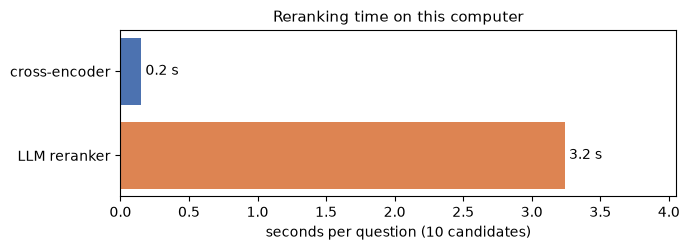

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
names = list(timings)
averages = [sum(values) / len(values) for values in timings.values()]
bars = ax.barh(names, averages, color=["#4C72B0", "#DD8452"])
for bar, seconds in zip(bars, averages, strict=True):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {seconds:.1f} s", va="center")
ax.set_xlabel("seconds per question (10 candidates)")
ax.set_xlim(0, max(averages) * 1.25)
ax.invert_yaxis()
ax.set_title("Reranking time on this computer", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "reranker_time.png", dpi=120)
plt.show()

The cross-encoder is fast enough for every question. The LLM reranker can fix harder cases,
but it adds seconds to every answer. Two questions prove little either way; Notebook 3
measures both on the whole test set.

A reranker can only reorder what the first stage found. If the right chunk is not in the
candidate set, no reranker can bring it back. That is why the first stage should cast a
wide net (hybrid, top 10) and the reranker should cut it down.

## 6. Which method when?

| Method | Good for | Cost | Watch out for |
|---|---|---|---|
| Vector search | Other words, same meaning | One embedding per question | Blurs exact numbers, codes, and names |
| BM25 | Exact terms: numbers, codes, names | Very cheap, no model | Misses other words for the same thing |
| Hybrid (RRF) | Both kinds of questions | Two searches and a merge | The right chunk is not always first |
| Auto-merging | Precise matches that need more context | A three-level index | Merges too much with a low threshold |
| Cross-encoder reranker | Better order, fast | A small local model | Can be fooled by shared words |
| LLM reranker | Harder questions | Seconds per question | Slow; may return fewer chunks |

A strong default: hybrid search for a candidate set of about 10, then a cross-encoder. Use
the LLM reranker where answers matter more than speed.

## 7. Summary

| Idea | What it means | In LlamaIndex |
|---|---|---|
| Dense retrieval | Rank by meaning, with embeddings | `VectorStoreIndex(...).as_retriever()` |
| Sparse retrieval | Rank by matching words; BM25 | `BM25Retriever.from_defaults(nodes=...)` |
| Hybrid search | Run both, merge the lists by rank | `QueryFusionRetriever(..., mode="reciprocal_rerank")` |
| Auto-merging | Search leaves, swap many matching leaves for their parent | `HierarchicalNodeParser`, `AutoMergingRetriever` |
| Reranking | Score question and candidate together, reorder a short list | `SentenceTransformerRerank`, `LLMRerank` |

**Remember:** first find the right chunk somewhere in a short list (hybrid), then put it
first (reranking).

➡️ **Next:** [Notebook 3 — Measuring retrieval](03_retrieval_evaluation.ipynb)